# GPT-2 From Scratch: A Decoder-Only Transformer

## 1. Project Overview

This project implements a small GPT-2-style language model from scratch using PyTorch.

The model learns to predict the next character in a sequence using:
- Character-level tokenization
- Token and learned positional embeddings
- Causal scaled dot-product self-attention
- Multi-head attention
- Feed-forward networks with GELU
- Pre-LayerNorm and residual connections
- Autoregressive text generation

**Dataset:** Tiny Shakespeare

**Architecture:** 2 Transformer blocks, 4 attention heads, embedding dimension 128.

The objective is to understand and implement the internal components of a GPT-2-style decoder-only Transformer without using pretrained models or existing Transformer implementations.

## 2. Imports and Reproducibility

We import the libraries required for:
- Neural network implementation and automatic differentiation
- Numerical operations
- Dataset handling
- Visualization
- Reproducibility and checkpoint management

We also select the available computation device.

In [68]:
import sys
print(sys.executable)

c:\Users\yessi\OneDrive\Documentos\Bayesian Optimization\.venv\Scripts\python.exe


In [69]:
import os
import math
import time
import random
import urllib.request

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device selection
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Computation device:", device)

PyTorch version: 2.15.0+cpu
Computation device: cpu


## 3. Model Configuration

We use a deliberately small GPT-2-style architecture to make training practical on limited hardware.

| Parameter | Value |
|---|---:|
| Context length | 128 |
| Embedding dimension | 128 |
| Transformer layers | 2 |
| Attention heads | 4 |
| Head dimension | 32 |
| Feed-forward dimension | 512 |
| Dropout | 0.1 |
| Learning rate | 0.0003 |
| Batch size | 32 |
| Optimizer | AdamW |
| Activation | GELU |
| Normalization | Pre-LayerNorm |

The architecture is configurable so that we can experiment with different numbers of attention heads later.

In [70]:
config = {
    "context_length": 128,
    "d_model": 128,
    "n_layers": 2,
    "n_heads": 4,
    "dropout": 0.1,
    "learning_rate": 3e-4,
    "batch_size": 32,
    "max_iters": 1000,
    "eval_interval": 200,
    "grad_clip": 1.0,
}

config["head_dim"] = config["d_model"] // config["n_heads"]
config["ffn_dim"] = 4 * config["d_model"]

assert config["d_model"] % config["n_heads"] == 0

print("Configuration:")
for key, value in config.items():
    print(f"{key}: {value}")

Configuration:
context_length: 128
d_model: 128
n_layers: 2
n_heads: 4
dropout: 0.1
learning_rate: 0.0003
batch_size: 32
max_iters: 1000
eval_interval: 200
grad_clip: 1.0
head_dim: 32
ffn_dim: 512


In [71]:
# Create project directories
os.makedirs("data", exist_ok=True)
os.makedirs("checkpoints", exist_ok=True)

print("Project directories ready.")

Project directories ready.


## 4. Dataset Preparation — Tiny Shakespeare

We use the Tiny Shakespeare dataset, a collection of Shakespeare's works.

The task is character-level next-token prediction: given a sequence of characters, the model learns to predict the next character.

We download the dataset, inspect its contents, and divide it into training and validation sets.

- Training set: 90%
- Validation set: 10%

The training set is used to optimize model parameters. The validation set measures how well the model performs on unseen sequences.

In [72]:
# Download Tiny Shakespeare
DATA_URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
DATA_PATH = "data/input.txt"

if not os.path.exists(DATA_PATH):
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

with open(DATA_PATH, "r", encoding="utf-8") as f:
    text_data = f.read()

print("Dataset downloaded successfully.")
print("Total characters:", len(text_data))
print("Unique characters:", len(set(text_data)))
print("\nDataset preview:\n")
print(text_data[:500])

Dataset downloaded successfully.
Total characters: 1115394
Unique characters: 65

Dataset preview:

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor


## 5. Training and Validation Split

We divide the dataset into two parts while preserving the original text order.

The first 90% is used for training, and the remaining 10% is reserved for validation.

This allows us to evaluate whether the model generalizes beyond the sequences used during training.

In [73]:
split_index = int(0.9 * len(text_data))

train_text = text_data[:split_index]
val_text = text_data[split_index:]

print("Training characters:", len(train_text))
print("Validation characters:", len(val_text))
print("Training percentage:", len(train_text) / len(text_data) * 100)
print("Validation percentage:", len(val_text) / len(text_data) * 100)

Training characters: 1003854
Validation characters: 111540
Training percentage: 89.99994620734915
Validation percentage: 10.000053792650847


## 6. Character-Level Tokenizer

A language model processes numerical token IDs rather than raw text.

Our character-level tokenizer assigns a unique integer to every character in the vocabulary.

It implements two operations:

- **Encoding:** Converts characters into integer IDs.
- **Decoding:** Converts integer IDs back into readable text.

We construct the vocabulary using the training text. An unknown-token ID handles any character that appears only in the validation set.

This approach is simpler than BPE tokenization and allows us to focus on implementing the Transformer architecture.

In [74]:
class CharacterTokenizer:
    def __init__(self, training_text):
        characters = sorted(set(training_text))

        self.unk_token = "<UNK>"
        self.stoi = {ch: i for i, ch in enumerate(characters)}
        self.stoi[self.unk_token] = len(characters)

        self.itos = {i: ch for ch, i in self.stoi.items()}

    def encode(self, text):
        return [
            self.stoi.get(ch, self.stoi[self.unk_token])
            for ch in text
        ]

    def decode(self, ids):
        return "".join(
            self.itos.get(int(i), self.unk_token)
            for i in ids
        )

    def vocab_size(self):
        return len(self.stoi)


tokenizer = CharacterTokenizer(train_text)

vocab_size = tokenizer.vocab_size()

print("Vocabulary size:", vocab_size)

# Test encoding and decoding
sample = "Hello Shakespeare!"
encoded = tokenizer.encode(sample)
decoded = tokenizer.decode(encoded)

print("Original:", sample)
print("Encoded:", encoded)
print("Decoded:", decoded)
print("Tokenizer test:", decoded == sample)

Vocabulary size: 66
Original: Hello Shakespeare!
Encoded: [20, 43, 50, 50, 53, 1, 31, 46, 39, 49, 43, 57, 54, 43, 39, 56, 43, 2]
Decoded: Hello Shakespeare!
Tokenizer test: True


## 8. Input-Target Sequence Preparation

The model learns next-character prediction.

For every input sequence, the target sequence is shifted one position to the right.

For example:

Input:  `HELLO`
Target: `ELLO `

At each position, the model predicts the character that follows the current character.

We use a context length of 128 and a batch size of 32.

The resulting tensor dimensions are:

- Input: `(B, T)` = `(32, 128)`
- Target: `(B, T)` = `(32, 128)`

Where B is batch size and T is sequence length.

In [75]:
# Ensure training and validation tensors exist
if "train_data" not in globals():
    train_data = torch.tensor(tokenizer.encode(train_text), dtype=torch.long)

if "val_data" not in globals():
    val_data = torch.tensor(tokenizer.encode(val_text), dtype=torch.long)


def get_batch(split):
    data = train_data if split == "train" else val_data

    batch_size = config["batch_size"]
    context_length = config["context_length"]

    ix = torch.randint(
        len(data) - context_length - 1,
        (batch_size,)
    )

    x = torch.stack([data[i:i + context_length] for i in ix])
    y = torch.stack([data[i + 1:i + context_length + 1] for i in ix])

    return x.to(device), y.to(device)


# Test batch generation
xb, yb = get_batch("train")

print("Training tensor:", train_data.shape)
print("Validation tensor:", val_data.shape)
print("Input shape:", xb.shape)
print("Target shape:", yb.shape)

print("\nInput example:")
print(tokenizer.decode(xb[0].tolist()))

print("\nTarget example:")
print(tokenizer.decode(yb[0].tolist()))

assert xb.shape == (32, 128)
assert yb.shape == xb.shape
assert torch.equal(xb[:, 1:], yb[:, :-1])

print("\nAll batch preparation tests passed.")

Training tensor: torch.Size([1003854])
Validation tensor: torch.Size([111540])
Input shape: torch.Size([32, 128])
Target shape: torch.Size([32, 128])

Input example:
 passage.

Second Watchman:
Ay, wherefore else guard we his royal tent,
But to defend his person from night-foes?

WARWICK:
This

Target example:
passage.

Second Watchman:
Ay, wherefore else guard we his royal tent,
But to defend his person from night-foes?

WARWICK:
This 

All batch preparation tests passed.


## 9. Token and Positional Embeddings

The model needs to represent both the identity and position of each character.

**Token embeddings:** Convert each token ID into a learnable vector of dimension 128.

**Positional embeddings:** Assign a learnable vector to each position in the sequence.

The two embeddings are added together:

X = E_token + E_position

The resulting representation has shape `(B, T, d_model)`.

We use learned positional embeddings, following the GPT-2 architecture.

In [76]:
class TokenAndPositionEmbedding(nn.Module):
    def __init__(self, vocab_size, d_model, context_length, dropout):
        super().__init__()

        self.token_embedding = nn.Embedding(vocab_size, d_model)
        self.position_embedding = nn.Embedding(context_length, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, idx):
        B, T = idx.shape

        token_emb = self.token_embedding(idx)

        positions = torch.arange(T, device=idx.device)
        position_emb = self.position_embedding(positions)

        x = token_emb + position_emb
        return self.dropout(x)


embedding_layer = TokenAndPositionEmbedding(
    vocab_size,
    config["d_model"],
    config["context_length"],
    config["dropout"]
).to(device)

embedding_output = embedding_layer(xb)

print("Embedding output shape:", embedding_output.shape)
assert embedding_output.shape == (32, 128, 128)

Embedding output shape: torch.Size([32, 128, 128])


## 10. Scaled Dot-Product Causal Self-Attention

Self-attention allows each token to calculate how much attention it should pay to other tokens.

The input is projected into three representations:

- Query (Q): What information is this token looking for?
- Key (K): What information does each token contain?
- Value (V): What information does each token provide?

The attention calculation is:

Attention(Q,K,V) = softmax(QKᵀ / √d_k + M)V

Where:

- QKᵀ calculates similarity between queries and keys.
- √d_k stabilizes the magnitude of attention scores.
- M is the causal mask.

**Causal masking:** Future positions are assigned negative infinity before softmax. This ensures that a token cannot attend to characters that have not yet been generated.

For position i, only positions j ≤ i are accessible.

In [77]:
class CausalSelfAttention(nn.Module):
    def __init__(self, head_dim, context_length, dropout):
        super().__init__()

        self.head_dim = head_dim
        self.dropout = nn.Dropout(dropout)

        # Lower triangular causal mask
        mask = torch.tril(torch.ones(context_length, context_length))
        self.register_buffer("causal_mask", mask)

    def forward(self, q, k, v):
        T = q.size(-2)

        # Scaled dot-product attention scores
        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)

        # Prevent attention to future positions
        mask = self.causal_mask[:T, :T]
        scores = scores.masked_fill(mask == 0, float("-inf"))

        attention_weights = F.softmax(scores, dim=-1)
        attention_weights = self.dropout(attention_weights)

        output = attention_weights @ v

        return output, attention_weights

In [78]:
# Test causal attention independently

B, T, D = 2, 8, 32

test_q = torch.randn(B, 1, T, D, device=device)
test_k = torch.randn(B, 1, T, D, device=device)
test_v = torch.randn(B, 1, T, D, device=device)

attention_test = CausalSelfAttention(
    D, config["context_length"], 0.0
).to(device)

attention_output, attention_weights = attention_test(
    test_q, test_k, test_v
)

print("Attention output:", attention_output.shape)
print("Attention weights:", attention_weights.shape)

# Verify that future positions receive zero attention
future_attention = torch.triu(attention_weights, diagonal=1)

print("Maximum future attention:", future_attention.max().item())

assert attention_output.shape == (B, 1, T, D)
assert torch.allclose(future_attention, torch.zeros_like(future_attention))

print("Causal masking test passed.")

Attention output: torch.Size([2, 1, 8, 32])
Attention weights: torch.Size([2, 1, 8, 8])
Maximum future attention: 0.0
Causal masking test passed.


## 11. Multi-Head Self-Attention

Multi-head attention allows the model to learn different attention patterns simultaneously.

Instead of performing one attention calculation, we divide the embedding dimension into multiple heads.

Our configuration:

- Embedding dimension: 128
- Number of heads: 4
- Dimension per head: 32

Each head independently performs scaled dot-product attention.

The outputs are concatenated and passed through a final linear projection.

Tensor dimensions:

Input: `(B, T, 128)`

Q, K, V after splitting: `(B, 4, T, 32)`

Attention scores: `(B, 4, T, T)`

Concatenated output: `(B, T, 128)`

In [79]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, context_length, dropout):
        super().__init__()

        assert d_model % n_heads == 0

        self.n_heads = n_heads
        self.head_dim = d_model // n_heads
        self.d_model = d_model

        # Combined projection for queries, keys and values
        self.qkv_projection = nn.Linear(d_model, 3 * d_model)

        self.attention = CausalSelfAttention(
            self.head_dim, context_length, dropout
        )

        self.output_projection = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape

        qkv = self.qkv_projection(x)
        q, k, v = qkv.chunk(3, dim=-1)

        # Split embedding dimension into attention heads
        q = q.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)

        # Apply attention independently to each head
        out, weights = self.attention(q, k, v)

        # Concatenate heads
        out = out.transpose(1, 2).contiguous().view(B, T, C)

        out = self.output_projection(out)
        out = self.dropout(out)

        return out


mha = MultiHeadSelfAttention(
    config["d_model"],
    config["n_heads"],
    config["context_length"],
    config["dropout"]
).to(device)

mha_output = mha(embedding_output)

print("Input shape:", embedding_output.shape)
print("Multi-head attention output:", mha_output.shape)

assert mha_output.shape == embedding_output.shape
print("Multi-head attention test passed.")

Input shape: torch.Size([32, 128, 128])
Multi-head attention output: torch.Size([32, 128, 128])
Multi-head attention test passed.


## 12. Position-Wise Feed-Forward Network

After attention, each token representation passes through a feed-forward neural network.

The network consists of:

1. Linear projection from 128 to 512 dimensions.
2. GELU activation.
3. Linear projection from 512 back to 128 dimensions.
4. Dropout.

Mathematically:

FFN(x) = W₂ GELU(W₁x + b₁) + b₂

The same feed-forward network is applied independently to every sequence position.

The output dimension remains 128.

In [80]:
class FeedForward(nn.Module):
    def __init__(self, d_model, ffn_dim, dropout):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(d_model, ffn_dim),
            nn.GELU(),
            nn.Linear(ffn_dim, d_model),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        return self.network(x)


ffn = FeedForward(
    config["d_model"],
    config["ffn_dim"],
    config["dropout"]
).to(device)

ffn_output = ffn(embedding_output)

print("FFN output shape:", ffn_output.shape)
assert ffn_output.shape == embedding_output.shape

print("Feed-forward network test passed.")

FFN output shape: torch.Size([32, 128, 128])
Feed-forward network test passed.


## 13. Layer Normalization and Residual Connections

**Layer Normalization**

LayerNorm normalizes activations across the embedding dimension for each token.

LN(x) = γ ((x - μ) / √(σ² + ε)) + β

Where γ and β are learnable parameters.

**Residual Connections**

Residual connections add the original input to the output of a sublayer.

They help preserve information and support gradient flow through deep networks.

**Pre-LayerNorm**

GPT-2 uses a Pre-LayerNorm arrangement.

For attention:

x' = x + Attention(LN₁(x))

For the feed-forward network:

y = x' + FFN(LN₂(x'))

Normalization happens before each sublayer, while residual addition happens afterward.

## 14. Transformer Block

A Transformer block combines multi-head self-attention, feed-forward processing, LayerNorm, and residual connections.

Its processing order is:

1. Normalize the input.
2. Apply causal multi-head self-attention.
3. Add the attention output to the original input.
4. Normalize the result.
5. Apply the feed-forward network.
6. Add the feed-forward output through another residual connection.

The block preserves the input shape `(B, T, 128)`.

In [81]:
class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, ffn_dim, context_length, dropout):
        super().__init__()

        self.ln1 = nn.LayerNorm(d_model)
        self.attention = MultiHeadSelfAttention(
            d_model, n_heads, context_length, dropout
        )

        self.ln2 = nn.LayerNorm(d_model)
        self.ffn = FeedForward(d_model, ffn_dim, dropout)

    def forward(self, x):
        # Pre-LayerNorm attention with residual connection
        x = x + self.attention(self.ln1(x))

        # Pre-LayerNorm feed-forward with residual connection
        x = x + self.ffn(self.ln2(x))

        return x


block = TransformerBlock(
    config["d_model"],
    config["n_heads"],
    config["ffn_dim"],
    config["context_length"],
    config["dropout"]
).to(device)

block_output = block(embedding_output)

print("Transformer block input:", embedding_output.shape)
print("Transformer block output:", block_output.shape)

assert block_output.shape == embedding_output.shape
assert torch.isfinite(block_output).all()

print("Transformer block tests passed.")

Transformer block input: torch.Size([32, 128, 128])
Transformer block output: torch.Size([32, 128, 128])
Transformer block tests passed.


## 15. GPT-2 Language Model Assembly

We now combine the components into a complete decoder-only Transformer.

The architecture consists of:

1. Token embeddings.
2. Learned positional embeddings.
3. Two Transformer blocks.
4. Final LayerNorm.
5. Linear language-model output head.

The model receives token IDs of shape `(B, T)` and produces logits of shape `(B, T, V)`.

Where:
- B = batch size
- T = sequence length
- V = vocabulary size

Each position produces a score for every possible next character.

We also tie the token embedding and output projection weights, following GPT-2's weight-sharing approach.

In [82]:
class GPT2LanguageModel(nn.Module):
    def __init__(self, vocab_size, config):
        super().__init__()

        self.context_length = config["context_length"]

        self.embeddings = TokenAndPositionEmbedding(
            vocab_size,
            config["d_model"],
            config["context_length"],
            config["dropout"]
        )

        self.blocks = nn.Sequential(*[
            TransformerBlock(
                config["d_model"],
                config["n_heads"],
                config["ffn_dim"],
                config["context_length"],
                config["dropout"]
            )
            for _ in range(config["n_layers"])
        ])

        self.final_ln = nn.LayerNorm(config["d_model"])
        self.lm_head = nn.Linear(config["d_model"], vocab_size, bias=False)

        # Weight tying: share token embedding and output projection weights
        self.lm_head.weight = self.embeddings.token_embedding.weight

    def forward(self, idx, targets=None):
        B, T = idx.shape

        if T > self.context_length:
            raise ValueError("Sequence exceeds context length.")

        x = self.embeddings(idx)
        x = self.blocks(x)
        x = self.final_ln(x)

        logits = self.lm_head(x)

        loss = None
        if targets is not None:
            B, T, V = logits.shape

            loss = F.cross_entropy(
                logits.view(B * T, V),
                targets.view(B * T)
            )

        return logits, loss


model = GPT2LanguageModel(vocab_size, config).to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Total parameters: 421,632
Trainable parameters: 421,632


In [83]:
class GPT2LanguageModel(nn.Module):
    def __init__(self, vocab_size, config):
        super().__init__()

        self.context_length = config["context_length"]

        self.embeddings = TokenAndPositionEmbedding(
            vocab_size,
            config["d_model"],
            config["context_length"],
            config["dropout"]
        )

        self.blocks = nn.Sequential(*[
            TransformerBlock(
                config["d_model"],
                config["n_heads"],
                config["ffn_dim"],
                config["context_length"],
                config["dropout"]
            )
            for _ in range(config["n_layers"])
        ])

        self.final_ln = nn.LayerNorm(config["d_model"])
        self.lm_head = nn.Linear(config["d_model"], vocab_size, bias=False)

        # Weight tying: share token embedding and output projection weights
        self.lm_head.weight = self.embeddings.token_embedding.weight

    def forward(self, idx, targets=None):
        B, T = idx.shape

        if T > self.context_length:
            raise ValueError("Sequence exceeds context length.")

        x = self.embeddings(idx)
        x = self.blocks(x)
        x = self.final_ln(x)

        logits = self.lm_head(x)

        loss = None
        if targets is not None:
            B, T, V = logits.shape

            loss = F.cross_entropy(
                logits.view(B * T, V),
                targets.view(B * T)
            )

        return logits, loss


model = GPT2LanguageModel(vocab_size, config).to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Total parameters: 421,632
Trainable parameters: 421,632


## 16. Model Forward-Pass Verification

Before training, we verify that the complete model processes a batch correctly.

Expected dimensions:

- Input: `(32, 128)`
- Logits: `(32, 128, vocabulary_size)`
- Loss: scalar

The logits contain unnormalized scores for the next-character prediction task.

In [84]:
model.eval()

with torch.no_grad():
    test_logits, test_loss = model(xb, yb)

print("Input shape:", xb.shape)
print("Logits shape:", test_logits.shape)
print("Loss:", test_loss.item())

assert test_logits.shape == (32, 128, vocab_size)
assert torch.isfinite(test_logits).all()
assert torch.isfinite(test_loss)

print("Complete model forward-pass test passed.")

Input shape: torch.Size([32, 128])
Logits shape: torch.Size([32, 128, 66])
Loss: 84.7112808227539
Complete model forward-pass test passed.


## 17. Next-Token Prediction Loss

We train the model using categorical cross-entropy.

At every sequence position, the model predicts a probability distribution over the vocabulary.

Cross-entropy measures the difference between the predicted distribution and the correct next character.

The loss is calculated using:

L = -1/N Σ log(P(correct next token))

PyTorch's CrossEntropyLoss expects raw logits, so we do not apply softmax before calculating the loss.

The model learns by minimizing this loss through backpropagation.

In [85]:
criterion = nn.CrossEntropyLoss()

# Verify loss calculation independently
logits, _ = model(xb)

B, T, V = logits.shape

manual_loss = criterion(
    logits.reshape(B * T, V),
    yb.reshape(B * T)
)

print("Cross-entropy loss:", manual_loss.item())

Cross-entropy loss: 84.7112808227539


## 18. Training and Validation

We train the model using AdamW, an optimizer that combines adaptive gradient updates with decoupled weight decay.

Each training iteration performs:

1. Sample a batch of input-target sequences.
2. Perform a forward pass.
3. Calculate cross-entropy loss.
4. Clear previous gradients.
5. Calculate gradients through backpropagation.
6. Clip gradients to prevent excessively large updates.
7. Update model parameters using AdamW.

Validation is performed periodically without updating model parameters.

We track both training and validation loss to monitor learning and detect overfitting.

In [86]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=config["learning_rate"]
)

@torch.no_grad()
def estimate_loss(eval_batches=30):
    model.eval()

    results = {}

    for split in ["train", "val"]:
        losses = []

        for _ in range(eval_batches):
            x, y = get_batch(split)
            _, loss = model(x, y)
            losses.append(loss.item())

        results[split] = np.mean(losses)

    model.train()
    return results


# Training history
train_losses = []
val_losses = []
training_steps = []

best_val_loss = float("inf")
start_time = time.time()

print("Training preparation complete.")
print("Device:", device)
print("Parameters:", f"{total_params:,}")
print("Maximum iterations:", config["max_iters"])

Training preparation complete.
Device: cpu
Parameters: 421,632
Maximum iterations: 1000


## 19. Model Training

We train for up to 2,000 iterations, evaluating the model every 200 iterations.

The training budget can be adjusted depending on available hardware and execution time.

The best checkpoint is selected using validation loss rather than training loss alone.

In [87]:
max_iters = config["max_iters"]
eval_interval = config["eval_interval"]

model.train()

for iteration in range(max_iters):

    # Evaluate periodically
    if iteration % eval_interval == 0 or iteration == max_iters - 1:
        losses = estimate_loss()

        train_losses.append(losses["train"])
        val_losses.append(losses["val"])
        training_steps.append(iteration)

        elapsed = time.time() - start_time

        print(
            f"Step {iteration:4d} | "
            f"Train loss: {losses['train']:.4f} | "
            f"Val loss: {losses['val']:.4f} | "
            f"Time: {elapsed:.1f}s"
        )

        if losses["val"] < best_val_loss:
            best_val_loss = losses["val"]

            torch.save({
                "iteration": iteration,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "config": config,
                "vocab_size": vocab_size,
                "best_val_loss": best_val_loss,
            }, "checkpoints/best_model.pt")

    # Sample training batch
    x, y = get_batch("train")

    # Forward pass
    logits, loss = model(x, y)

    # Backpropagation
    optimizer.zero_grad(set_to_none=True)
    loss.backward()

    # Gradient clipping
    torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        config["grad_clip"]
    )

    # Parameter update
    optimizer.step()


training_time = time.time() - start_time

print("\nTraining completed.")
print(f"Total training time: {training_time / 60:.2f} minutes")
print(f"Best validation loss: {best_val_loss:.4f}")

Step    0 | Train loss: 84.7596 | Val loss: 84.5675 | Time: 2.8s
Step  200 | Train loss: 2.8606 | Val loss: 2.9087 | Time: 64.6s
Step  400 | Train loss: 2.6861 | Val loss: 2.7191 | Time: 136.2s
Step  600 | Train loss: 2.6130 | Val loss: 2.6288 | Time: 211.2s
Step  800 | Train loss: 2.5638 | Val loss: 2.5887 | Time: 276.3s
Step  999 | Train loss: 2.5508 | Val loss: 2.5507 | Time: 340.7s

Training completed.
Total training time: 5.68 minutes
Best validation loss: 2.5507


## 20. Training Visualization

We visualize training and validation loss over the training iterations.

Training loss measures how well the model fits the training data.

Validation loss measures how well the model predicts unseen data.

We compare both curves to identify:
- Whether the model is learning.
- Whether validation performance improves.
- Whether overfitting occurs.

A decreasing loss generally indicates that the model is learning useful patterns.

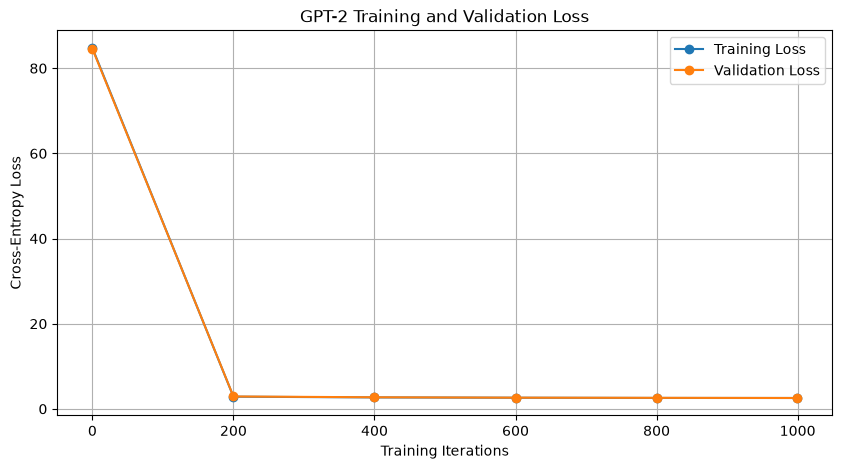

In [88]:
plt.figure(figsize=(10, 5))

plt.plot(training_steps, train_losses, marker="o", label="Training Loss")
plt.plot(training_steps, val_losses, marker="o", label="Validation Loss")

plt.xlabel("Training Iterations")
plt.ylabel("Cross-Entropy Loss")
plt.title("GPT-2 Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

## 21. Perplexity Evaluation

Perplexity measures how uncertain a language model is when predicting the next token.

It is calculated as:

Perplexity = exp(Cross-Entropy Loss)

Lower perplexity generally indicates better next-token prediction.

We calculate perplexity using the best validation loss obtained during training.

In [89]:
best_val_perplexity = math.exp(best_val_loss)

print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Validation perplexity: {best_val_perplexity:.4f}")

Best validation loss: 2.5507
Validation perplexity: 12.8162


## 22. Model Checkpointing

A checkpoint stores the model's learned parameters and training information.

This allows us to restore the best-performing model without training it again.

We load the checkpoint with the lowest recorded validation loss.

In [90]:
checkpoint = torch.load(
    "checkpoints/best_model.pt",
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Best checkpoint loaded successfully.")
print("Saved iteration:", checkpoint["iteration"])
print("Saved validation loss:", checkpoint["best_val_loss"])

Best checkpoint loaded successfully.
Saved iteration: 999
Saved validation loss: 2.550712474187215


## 23. Autoregressive Text Generation

The model generates text one character at a time.

The generation process is:

1. Receive an initial prompt.
2. Pass the prompt through the model.
3. Extract the logits at the final sequence position.
4. Select the next character.
5. Append the predicted character to the sequence.
6. Repeat until the requested number of characters is generated.

We implement two decoding strategies:

**Greedy decoding:** Selects the character with the highest predicted probability.

**Temperature sampling:** Adjusts the probability distribution before randomly sampling the next character.

Temperature modifies the distribution as follows:

P(x) = softmax(logits / T)

- Low temperature produces more predictable outputs.
- High temperature produces more varied outputs.

In [91]:
@torch.no_grad()
def generate(model, tokenizer, prompt, max_new_tokens=300, temperature=1.0):
    model.eval()

    if temperature <= 0:
        raise ValueError("Temperature must be greater than zero.")

    # Encode the initial prompt
    idx = torch.tensor(
        [tokenizer.encode(prompt)],
        dtype=torch.long,
        device=device
    )

    for _ in range(max_new_tokens):

        # Keep only the most recent context window
        idx_cond = idx[:, -model.context_length:]

        # Predict next-token logits
        logits, _ = model(idx_cond)

        # Select logits from the final position
        logits = logits[:, -1, :]

        # Apply temperature
        logits = logits / temperature

        # Convert logits into probabilities
        probabilities = F.softmax(logits, dim=-1)

        # Greedy decoding when temperature is extremely low
        if temperature <= 0.01:
            next_token = torch.argmax(logits, dim=-1, keepdim=True)
        else:
            next_token = torch.multinomial(probabilities, num_samples=1)

        # Append predicted character
        idx = torch.cat((idx, next_token), dim=1)

    return tokenizer.decode(idx[0].tolist())

In [92]:
# Greedy generation
prompt = "ROMEO: "

greedy_output = generate(
    model,
    tokenizer,
    prompt,
    max_new_tokens=300,
    temperature=0.01
)

print("GREEDY GENERATION")
print("-" * 60)
print(greedy_output)

GREEDY GENERATION
------------------------------------------------------------
ROMEO: the the the the are the an the the the the t the the the the the the the the the the t the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the t


In [93]:
# Temperature-based generation
sampled_output = generate(
    model,
    tokenizer,
    prompt,
    max_new_tokens=300,
    temperature=0.8
)

print("TEMPERATURE SAMPLING")
print("-" * 60)
print(sampled_output)

TEMPERATURE SAMPLING
------------------------------------------------------------
ROMEO: ar tor tereyoo a l darsthanthe norstes, thedoalug tun tou thace

B ayo we st me us l s rer s f be the,

Aithe t thoto t s theay d souulouteane o s the oome,


Pe ar iwhe bore wishe---in.
We, th thentafotou y weamas is ay d t ome me; t in,

Se GGGG f stousur bu!

Pines ING ut Whome wirnd t th;ing fe 


## 24. Experiment 1: Effect of Temperature

We investigate how temperature affects generated text.

We use the same model and initial prompt while changing the sampling temperature.

Values tested:
- 0.3
- 0.7
- 1.0
- 1.5

We compare the resulting outputs in terms of:
- Repetition
- Diversity
- Predictability
- Linguistic coherence

All other generation settings remain constant.

In [94]:
temperatures = [0.3, 0.7, 1.0, 1.5]

temperature_results = {}

for temp in temperatures:
    output = generate(
        model,
        tokenizer,
        prompt,
        max_new_tokens=200,
        temperature=temp
    )

    temperature_results[temp] = output

    print(f"\nTEMPERATURE = {temp}")
    print("-" * 60)
    print(output)


TEMPERATURE = 0.3
------------------------------------------------------------
ROMEO: the the are the the me there s than the here four the the the the be herore ore are the there the the an t the an the at o the o the the the the the the the ithe the the the thoure thathe the the the 

TEMPERATURE = 0.7
------------------------------------------------------------
ROMEO: itht oul illlis ar the o
Eed, d licare an f ay sered ar ghou hatand yer s than ge arf we foouse woure t ve at to y beateesthe,

Wly ghatous hout t
S I the pero cene, yothe wait cou,

Phere ace the th 

TEMPERATURE = 1.0
------------------------------------------------------------
ROMEO: f lld mutharany cive I ble lyh anFe at thenigr aretee y:
G othas ptaso
Arer mokhe j thwirRRKe r wtl nt betheit y me d tanche, he fecead o wer af tes t sy d iede in Girabstathe mafsthanyor te dellot ty

TEMPERATURE = 1.5
------------------------------------------------------------
ROMEO: V myy'eday AS onct reavind, De isyo tod!, bi'l s:

## 25. Experiment 2: Effect of Prompt Length

We investigate how the amount of initial context affects generated text.

We compare prompts of different lengths while keeping the model, temperature, and generation length constant.

A longer prompt provides more preceding information to the model, potentially influencing its predictions.

We do not assume that longer prompts always produce better outputs; the results must be evaluated from actual generations.

In [95]:
base_prompt = "ROMEO: What is the meaning of love and what shall we do?"

prompt_lengths = [10, 30, 60]

context_results = {}

for length in prompt_lengths:
    current_prompt = base_prompt[:length]

    output = generate(
        model,
        tokenizer,
        current_prompt,
        max_new_tokens=200,
        temperature=0.8
    )

    context_results[length] = output

    print(f"\nPROMPT LENGTH = {length}")
    print("Prompt:", repr(current_prompt))
    print("-" * 60)
    print(output)


PROMPT LENGTH = 10
Prompt: 'ROMEO: Wha'
------------------------------------------------------------
ROMEO: Whand torotoan, inr,
Be ce, ms I pal hare an t oure ween

Fore y w se Basche he, ed the d cole dr,
Touroreounothe wo oad an e hele INCAn s hathe ad gicalythe coma, he mee t matheathar ind le,

Forang ant

PROMPT LENGTH = 30
Prompt: 'ROMEO: What is the meaning of '
------------------------------------------------------------
ROMEO: What is the meaning of in fy my wit he t thifowe gy ice ditofofotat nof rourd t ais th to

There are ath to veul anutim,
A orathee ol one buse, ne alite aicathiceay l the, wiisto's s me y t cho onou tea h t whe oun ofo,

Rp

PROMPT LENGTH = 60
Prompt: 'ROMEO: What is the meaning of love and what shall we do?'
------------------------------------------------------------
ROMEO: What is the meaning of love and what shall we do?
Ane foupere mse thonerit tingh athid n,

Ft ginid men:
TEd ayotheromen towin the athethend ite at t the br t
Seayonou thalin r as

## 26. Experiment 3: Effect of Number of Attention Heads

We investigate how changing the number of attention heads affects model performance.

We compare:

**Model A**
- Embedding dimension: 128
- Attention heads: 4
- Transformer layers: 2

**Model B**
- Embedding dimension: 128
- Attention heads: 2
- Transformer layers: 2

All other training settings remain the same.

We compare:
- Parameter count
- Training loss
- Validation loss
- Perplexity
- Training time

Changing the number of heads while keeping the embedding dimension fixed does not necessarily change the parameter count when using combined QKV projections. It changes how the representation is divided across attention heads.

In [96]:
# Build Model B with two attention heads
experiment_config = config.copy()
experiment_config["n_heads"] = 2

model_b = GPT2LanguageModel(
    vocab_size,
    experiment_config
).to(device)

params_b = sum(p.numel() for p in model_b.parameters())

print("Model A (4 heads) parameters:", f"{total_params:,}")
print("Model B (2 heads) parameters:", f"{params_b:,}")

assert params_b == total_params

print("Parameter-count comparison passed.")

Model A (4 heads) parameters: 421,632
Model B (2 heads) parameters: 421,632
Parameter-count comparison passed.


In [97]:
# Train Model B using the same training budget

optimizer_b = torch.optim.AdamW(
    model_b.parameters(),
    lr=config["learning_rate"]
)

model_b.train()

start_b = time.time()

for iteration in range(config["max_iters"]):

    x, y = get_batch("train")

    logits, loss = model_b(x, y)

    optimizer_b.zero_grad(set_to_none=True)
    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        model_b.parameters(),
        config["grad_clip"]
    )

    optimizer_b.step()

    if iteration % config["eval_interval"] == 0 or iteration == config["max_iters"] - 1:
        model_b.eval()

        with torch.no_grad():
            _, val_loss_b = model_b(*get_batch("val"))

        print(
            f"Model B | Step {iteration} | "
            f"Training loss: {loss.item():.4f} | "
            f"Validation loss: {val_loss_b.item():.4f}"
        )

        model_b.train()


time_b = time.time() - start_b

model_b.eval()

with torch.no_grad():
    _, final_train_loss_b = model_b(*get_batch("train"))
    _, final_val_loss_b = model_b(*get_batch("val"))

print("\nModel B training completed.")
print("Training time:", round(time_b / 60, 2), "minutes")
print("Final training loss:", round(final_train_loss_b.item(), 4))
print("Final validation loss:", round(final_val_loss_b.item(), 4))
print("Final validation perplexity:", round(math.exp(final_val_loss_b.item()), 4))

Model B | Step 0 | Training loss: 82.6395 | Validation loss: 84.5951
Model B | Step 200 | Training loss: 3.8002 | Validation loss: 2.9956
Model B | Step 400 | Training loss: 3.0960 | Validation loss: 2.7428
Model B | Step 600 | Training loss: 2.8702 | Validation loss: 2.6893
Model B | Step 800 | Training loss: 2.7685 | Validation loss: 2.5522
Model B | Step 999 | Training loss: 2.7112 | Validation loss: 2.5410

Model B training completed.
Training time: 4.77 minutes
Final training loss: 2.5012
Final validation loss: 2.5425
Final validation perplexity: 12.7111


In [99]:
# Compare the two architectures

comparison = {
    "Model A (4 heads)": {
        "Parameters": total_params,
        "Validation Loss": best_val_loss,
        "Perplexity": math.exp(best_val_loss),
        "Training Time (seconds)": training_time
    },
    "Model B (2 heads)": {
        "Parameters": params_b,
        "Validation Loss": final_val_loss_b.item(),
        "Perplexity": math.exp(final_val_loss_b.item()),
        "Training Time (seconds)": time_b
    }
}

import pandas as pd

comparison_df = pd.DataFrame(comparison).T
display(comparison_df)

,Parameters,Validation Loss,Perplexity,Training Time (seconds)
Model A (4 heads),421632.0,2.550712,12.816232,341.064177
Model B (2 heads),421632.0,2.542478,12.711125,286.413537


## 27. Final Model Evaluation

We evaluate both architectures using multiple batches rather than relying on a single randomly selected batch.

This provides a more stable estimate of training and validation loss.

We calculate:
- Average training loss
- Average validation loss
- Validation perplexity
- Total trainable parameters

These metrics provide a quantitative basis for comparing the two architectures.

In [100]:
@torch.no_grad()
def evaluate_model(model, eval_batches=30):
    model.eval()

    results = {}

    for split in ["train", "val"]:
        losses = []

        for _ in range(eval_batches):
            x, y = get_batch(split)
            _, loss = model(x, y)
            losses.append(loss.item())

        results[split] = float(np.mean(losses))

    model.train()
    return results


# Evaluate both models consistently
results_a = evaluate_model(model)
results_b = evaluate_model(model_b)

final_results = {
    "Model A (4 heads)": {
        "Parameters": total_params,
        "Train Loss": results_a["train"],
        "Validation Loss": results_a["val"],
        "Perplexity": math.exp(results_a["val"]),
        "Training Time (seconds)": training_time
    },
    "Model B (2 heads)": {
        "Parameters": params_b,
        "Train Loss": results_b["train"],
        "Validation Loss": results_b["val"],
        "Perplexity": math.exp(results_b["val"]),
        "Training Time (seconds)": time_b
    }
}

final_results_df = pd.DataFrame(final_results).T

display(final_results_df.round(4))

,Parameters,Train Loss,Validation Loss,Perplexity,Training Time (seconds)
Model A (4 heads),421632.0,2.5415,2.5532,12.8479,341.0642
Model B (2 heads),421632.0,2.5293,2.5419,12.7039,286.4135


In [ ]:
# Save Model B checkpoint

torch.save({
    "model_state_dict": model_b.state_dict(),
    "config": experiment_config,
    "validation_loss": results_b["val"],
    "vocab_size": vocab_size,
}, "checkpoints/model_b.pt")

print("Model B checkpoint saved successfully.")
print("Model A checkpoint:", os.path.exists("checkpoints/best_model.pt"))
print("Model B checkpoint:", os.path.exists("checkpoints/model_b.pt"))

## 28. Comparison of Generated Text

We compare text generated by the two architectures using the same prompt and generation settings.

This provides a qualitative comparison of their generation behavior.

We examine:
- Character and word repetition
- Sentence structure
- Shakespeare-like language patterns
- Continuity and coherence
- Differences in generated content

Generated text is evaluated qualitatively. A fluent-looking sample alone does not establish that one architecture is objectively better.

In [101]:
comparison_prompt = "ROMEO: "

output_a = generate(
    model,
    tokenizer,
    comparison_prompt,
    max_new_tokens=300,
    temperature=0.8
)

output_b = generate(
    model_b,
    tokenizer,
    comparison_prompt,
    max_new_tokens=300,
    temperature=0.8
)

print("MODEL A — FOUR HEADS")
print("=" * 60)
print(output_a)

print("\nMODEL B — TWO HEADS")
print("=" * 60)
print(output_b)

MODEL A — FOUR HEADS
ROMEO: in an,
LLAfthe y to t at ave the t out, he of ithelath?
Mithe toulaitofour cike f t y Who se m it rase corI inor, thtik ad me ou ty m tougee ame osthithe it touepsery ine e the tothe or w m t a yiin myoavemeriton w e t ande th thele Wifour thay fathe ino nan th yonthe t at ore teno ce ithe the,

Bf 

MODEL B — TWO HEADS
ROMEO: sis chacor tout Busen inge t me ll lat s otesecowhion pererdind ngotarenghet g d m the t:
Heat?
A te f the d w, velthing d be the thandor f anous d dstu hes thito theyoury s thece ot hounoat l let wot the.

I its conge mont rsownd hee and ad ano bree atand watindlieathegang homelonisin s.
NE ate ota


## 29. Experimental Findings

### Experiment 1: Temperature

The temperature experiment examined how sampling temperature affects generated text.

Observed findings:
- Temperature 0.3:
- Temperature 0.7:
- Temperature 1.0:
- Temperature 1.5:

### Experiment 2: Prompt Length

The prompt-length experiment examined how different amounts of initial context influence generation.

Observed findings:
- 10-character prompt:
- 30-character prompt:
- 60-character prompt:

### Experiment 3: Number of Attention Heads

The architectural experiment compared a four-head model against a two-head model.

Observed findings:
- Four-head validation loss:
- Two-head validation loss:
- Parameter count:
- Training-time difference:
- Qualitative generation differences:

### Overall Interpretation

The experiments demonstrate how model configuration and generation settings influence language-model behavior.

Conclusions must be based on the measured results rather than assumptions about which configuration should perform better.

## 30. Implementation Challenges

The implementation involved several important technical challenges:

1. **Causal masking:** Ensuring that each position could only attend to previous and current positions.
2. **Tensor dimensions:** Correctly reshaping and splitting queries, keys, and values across attention heads.
3. **Next-token alignment:** Ensuring that input and target sequences were shifted by exactly one position.
4. **Training stability:** Using dropout, AdamW, gradient clipping, and Pre-LayerNorm.
5. **Computational constraints:** Selecting a sufficiently small architecture to make training practical.
6. **Autoregressive generation:** Maintaining the correct context window while generating tokens sequentially.

These challenges helped establish an understanding of both the mathematical principles and practical implementation of Transformer models.

## 31. Limitations and Future Improvements

### Limitations

1. **Character-level tokenization:** The model predicts individual characters rather than subword tokens, making it less efficient than modern language models.
2. **Small architecture:** Two Transformer blocks and an embedding dimension of 128 provide limited model capacity.
3. **Limited dataset:** Tiny Shakespeare is relatively small and represents a narrow language domain.
4. **Training budget:** The model receives substantially less training and data than production-scale GPT models.
5. **Computational resources:** Training time and architecture size are constrained by available hardware.
6. **Generation quality:** The model may produce grammatical errors, repetitions, and inconsistent passages.

### Future Improvements

- Implement Byte Pair Encoding (BPE) tokenization.
- Increase model depth and embedding dimension.
- Experiment with larger training datasets.
- Introduce learning-rate scheduling.
- Train for longer with appropriate computational resources.
- Evaluate generation using additional quantitative and qualitative metrics.

## 32. Conclusion

This project implemented a small GPT-2-style decoder-only Transformer from scratch using PyTorch.

The implementation covered the complete language-modeling pipeline, including tokenization, embeddings, causal self-attention, multi-head attention, feed-forward networks, normalization, residual connections, training, evaluation, and autoregressive generation.

The model was trained on Tiny Shakespeare using next-character prediction.

The experiments investigated the effects of sampling temperature, prompt length, and attention-head configuration.

Overall, the project provided practical experience with the mathematical foundations, architectural components, training process, and generation behavior of GPT-2-style language models.

The results also demonstrate the trade-offs associated with model capacity, computational cost, and generation quality.

In [102]:
print("PROJECT VERIFICATION")
print("=" * 50)

print("Dataset exists:", os.path.exists(DATA_PATH))
print("Tokenizer vocabulary:", vocab_size)
print("Model A parameters:", f"{total_params:,}")
print("Model B parameters:", f"{params_b:,}")
print("Model A checkpoint:", os.path.exists("checkpoints/best_model.pt"))

print("\nModel A validation loss:", round(results_a["val"], 4))
print("Model B validation loss:", round(results_b["val"], 4))

print("\nTraining time A:", round(training_time / 60, 2), "minutes")
print("Training time B:", round(time_b / 60, 2), "minutes")

print("\nAll major implementation components completed.")

PROJECT VERIFICATION
Dataset exists: True
Tokenizer vocabulary: 66
Model A parameters: 421,632
Model B parameters: 421,632
Model A checkpoint: True

Model A validation loss: 2.5532
Model B validation loss: 2.5419

Training time A: 5.68 minutes
Training time B: 4.77 minutes

All major implementation components completed.


In [103]:
# Save Model B checkpoint

torch.save({
    "model_state_dict": model_b.state_dict(),
    "config": experiment_config,
    "validation_loss": results_b["val"],
    "vocab_size": vocab_size,
}, "checkpoints/model_b.pt")

print("Model B checkpoint saved.")

Model B checkpoint saved.


In [ ]:
print("=" * 65)
print("EXPERIMENTAL RESULTS")
print("=" * 65)

print("\n1. MODEL COMPARISON")
print(f"4-head model validation loss: {results_a['val']:.4f}")
print(f"2-head model validation loss: {results_b['val']:.4f}")
print(f"4-head model parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"2-head model parameters: {sum(p.numel() for p in model_b.parameters()):,}")

print("\n2. TEMPERATURE EXPERIMENTS")
for temperature, output in temperature_results.items():
    print(f"\nTemperature: {temperature}")
    print(output[:250])

print("\n3. PROMPT LENGTH EXPERIMENTS")
for length, output in context_results.items():
    print(f"\nPrompt length: {length}")
    print(output[:250])

print("\n4. TRAINING")
print(f"Model A training time: {training_time / 60:.2f} minutes")
print(f"Model B training time: {time_b / 60:.2f} minutes")
print(f"Best Model A validation loss: {best_val_loss:.4f}")

# 1. The Transformer Architecture

The Transformer was introduced in the 2017 paper *Attention Is All You Need* by Vaswani et al.

Before Transformers, sequence-processing tasks primarily relied on Recurrent Neural Networks (RNNs), including LSTMs and GRUs. These architectures process sequences sequentially, making parallelization difficult and limiting how efficiently they capture long-range dependencies.

The Transformer introduced an architecture based entirely on attention mechanisms, removing recurrence from the main sequence-processing pathway.

## Original Encoder–Decoder Architecture

The original Transformer consists of two main components:

**Encoder:**
- Processes the input sequence.
- Uses multi-head self-attention.
- Uses position-wise feed-forward networks.
- Includes residual connections and Layer Normalization.

**Decoder:**
- Generates the output sequence.
- Uses masked multi-head self-attention.
- Uses encoder–decoder cross-attention to access encoder representations.
- Uses position-wise feed-forward networks.
- Includes residual connections and Layer Normalization.

The encoder produces contextual representations of the input. The decoder uses these representations to generate an output sequence.

Our implementation uses a decoder-only architecture inspired by GPT-2 rather than the original encoder–decoder structure.

# 2. RNNs, LSTMs, and Transformers

## Recurrent Neural Networks

An RNN processes a sequence one element at a time. At each time step, it combines the current input with the previous hidden state:

h_t = f(W_x x_t + W_h h_(t-1) + b)

Where:
- x_t is the current input.
- h_(t-1) is the previous hidden state.
- h_t is the updated hidden state.
- W_x and W_h are learned weight matrices.

The hidden state carries information from earlier elements in the sequence.

**Limitations:**
- Sequential computation makes parallelization difficult.
- Long-range dependencies can be difficult to preserve.
- Gradients may vanish or explode during training.

## Long Short-Term Memory Networks

LSTMs were designed to improve the ability of recurrent networks to preserve information over longer sequences.

They use a cell state and three main gates:

- Forget gate: determines what information to remove.
- Input gate: determines what new information to store.
- Output gate: determines what information to expose as the hidden state.

These gates help control information flow and reduce the vanishing-gradient problem.

However, LSTMs still process tokens sequentially.

## Transformers

Transformers use attention to establish relationships between sequence positions.

Instead of passing information through a recurrent hidden state, each position can directly attend to other permitted positions.

Advantages include:
- Parallel processing during training.
- Direct modeling of long-range dependencies.
- Multiple attention heads that learn different relationships.

| Property | RNN | LSTM | Transformer |
|---|---|---|---|
| Sequence processing | Sequential | Sequential | Parallel during training |
| Memory mechanism | Hidden state | Cell state and gates | Attention |
| Long-range dependencies | Difficult | Improved | Direct attention |
| Parallelization | Limited | Limited | High |
| Main challenge | Vanishing gradients | Sequential computation | Attention computation and memory |

# 3. Scaled Dot-Product Attention

Attention allows a model to determine which positions in a sequence are important when processing a particular token.

It operates using three representations:

- Query (Q): what information a token is looking for.
- Key (K): what information a token makes available.
- Value (V): the information that can be retrieved.

These representations are produced using learned linear projections:

Q = XW_Q
K = XW_K
V = XW_V

Where X represents the input sequence.

## Attention Formula

Attention(Q, K, V) = softmax(QK^T / sqrt(d_k))V

The computation involves four stages:

1. Calculate similarity scores using QK^T.
2. Scale the scores by sqrt(d_k).
3. Apply softmax to obtain attention weights.
4. Multiply the weights by V to produce the output.

## Why divide by sqrt(d_k)?

As the key dimension increases, dot-product values can become large.

Large values can cause softmax to produce extremely concentrated probabilities, resulting in small gradients.

Dividing by sqrt(d_k) helps control the magnitude of the scores and stabilizes training.

## Causal Masking

For autoregressive language modeling, a token must not access future tokens.

We apply a lower-triangular mask to the attention scores before softmax.

Future positions are assigned negative infinity:

masked_scores[i,j] = -infinity when j > i

After softmax, these positions receive zero attention probability.

This ensures that token position i can only use information from positions 0 through i.

# 4. Multi-Head Self-Attention

Instead of calculating attention once, multi-head attention performs several attention operations in parallel.

Each attention head has its own learned Query, Key, and Value projections.

For h attention heads:

MultiHead(Q,K,V) = Concat(head_1,...,head_h)W_O

Each head is calculated as:

head_i = Attention(QW_Q_i, KW_K_i, VW_V_i)

The outputs are concatenated and projected back into the model dimension.

## Why multiple heads?

Different heads can learn different relationships between tokens.

For example, one head may learn local relationships while another may capture relationships between more distant positions. These are possible learned behaviors, not predefined assignments.

## Our implementation

Our model uses:

- Model dimension: 128
- Number of heads: 4
- Dimension per head: 32

Therefore:

head_dim = 128 / 4 = 32

We also experimented with two heads:

head_dim = 128 / 2 = 64

Both configurations retain the same overall model dimension of 128.

The experiment helps investigate whether changing the number of attention heads affects validation performance and training time when the model dimension remains fixed.

# 5. Positional Information

Self-attention does not inherently understand the order of tokens.

Without positional information, the model would have difficulty distinguishing sequences containing the same tokens in different orders.

Transformers therefore introduce positional information into token representations.

## Positional Encoding in the Original Transformer

The original Transformer used sinusoidal positional encodings:

PE(pos, 2i) = sin(pos / 10000^(2i/d_model))

PE(pos, 2i+1) = cos(pos / 10000^(2i/d_model))

These functions provide position-dependent patterns using sine and cosine functions of different frequencies.

## GPT-2 Positional Embeddings

GPT-2 uses learned positional embeddings rather than fixed sinusoidal encodings.

Each position has a trainable embedding vector.

In our implementation:

token_representation = token_embedding + position_embedding

The resulting representation contains both token identity and position information.

Our model uses a context length of 128, meaning it supports sequences containing up to 128 token positions in one forward pass.

# 6. Feed-Forward Networks, Layer Normalization, and Residual Connections

## Position-wise Feed-Forward Network

After attention, each token representation passes through a feed-forward network.

Our implementation uses:

FFN(x) = W_2 GELU(W_1 x + b_1) + b_2

The dimensions are:

128 → 512 → 128

The first projection expands the representation, GELU introduces non-linearity, and the second projection returns it to the original model dimension.

Unlike attention, the feed-forward network processes each token position independently.

## Layer Normalization

Layer Normalization normalizes activations across the feature dimension for each token.

It helps stabilize the distribution of activations during training.

It applies learned scale and shift parameters after normalization.

## Residual Connections

Residual connections add the input of a sublayer to its output:

output = x + Sublayer(x)

They provide a direct path for information and gradients to flow through the network.

This makes deeper neural networks easier to optimize.

## Pre-LayerNorm in Our Model

Our implementation uses Pre-LayerNorm:

x = x + Attention(LayerNorm(x))

x = x + FFN(LayerNorm(x))

Normalization occurs before each major sublayer.

This differs from the Post-LayerNorm arrangement used in the original Transformer paper.

GPT-2 also uses a Pre-LayerNorm-style arrangement.

# 7. Types of Attention

## Unmasked Self-Attention

Every token can attend to every other token in the same sequence.

This is useful in encoder architectures, where the model can use both preceding and following context.

## Masked Self-Attention

A causal mask prevents a token from accessing future positions.

For example:

Token 1: can attend to token 1.
Token 2: can attend to tokens 1 and 2.
Token 3: can attend to tokens 1, 2, and 3.

This is essential for autoregressive generation.

## Cross-Attention

Cross-attention connects two different sequences.

Queries come from one sequence, while Keys and Values come from another.

In the original encoder–decoder Transformer:
- Queries come from the decoder.
- Keys and Values come from the encoder.

This allows the decoder to access information from the encoded input.

## Attention in Our GPT-2-Style Model

Our implementation uses causal masked self-attention.

It does not use encoder–decoder cross-attention because it has no separate encoder.

# 8. Original Transformer vs GPT-2

Although GPT-2 is based on the Transformer architecture, it makes several architectural choices that support autoregressive language modeling.

| Feature | Original Transformer | GPT-2 |
|---|---|---|
| Architecture | Encoder–decoder | Decoder-only |
| Main task | Sequence-to-sequence | Autoregressive language modeling |
| Attention | Encoder self-attention, masked decoder self-attention, cross-attention | Causal self-attention |
| Positional information | Sinusoidal | Learned positional embeddings |
| Layer normalization | Post-LayerNorm | Pre-LayerNorm |
| Output | Decoder sequence representations | Next-token probability distribution |

## Why Decoder-Only?

A decoder-only language model predicts the next token based on previously observed tokens.

Given:

x_1, x_2, ..., x_t

The model estimates:

P(x_(t+1) | x_1, x_2, ..., x_t)

It generates text by repeatedly predicting a next token and appending it to the existing sequence.

## Our Implementation

Our model follows the main GPT-2 architectural principles:

- Decoder-only architecture.
- Causal self-attention.
- Learned positional embeddings.
- Pre-LayerNorm.
- GELU feed-forward networks.
- Residual connections.
- Autoregressive next-token prediction.

However, this is a small GPT-2-style implementation, not an exact reproduction of the original GPT-2 model. It uses character-level tokenization, a much smaller architecture, and a smaller training dataset.

# 9. Complete Model Architecture and Data Flow

Our implementation follows a decoder-only Transformer architecture.

## Architecture Diagram

INPUT TEXT
    |
    v
CHARACTER TOKENIZER
    |
    v
TOKEN IDs
(B, T)
    |
    v
TOKEN EMBEDDING + POSITIONAL EMBEDDING
(B, T, 128)
    |
    v
TRANSFORMER BLOCK 1
    |
    |-- Layer Normalization
    |-- Multi-Head Causal Self-Attention
    |-- Residual Connection
    |-- Layer Normalization
    |-- Feed-Forward Network
    |-- Residual Connection
    |
    v
TRANSFORMER BLOCK 2
    |
    |-- Layer Normalization
    |-- Multi-Head Causal Self-Attention
    |-- Residual Connection
    |-- Layer Normalization
    |-- Feed-Forward Network
    |-- Residual Connection
    |
    v
FINAL LAYER NORMALIZATION
(B, T, 128)
    |
    v
LANGUAGE MODEL HEAD
(B, T, 66)
    |
    v
NEXT-TOKEN LOGITS
    |
    v
CROSS-ENTROPY LOSS DURING TRAINING
OR
AUTOREGRESSIVE TOKEN GENERATION

## Architecture Configuration

| Parameter | Value |
|---|---:|
| Vocabulary size | 66 |
| Context length | 128 |
| Model dimension | 128 |
| Transformer blocks | 2 |
| Attention heads | 4 |
| Head dimension | 32 |
| Feed-forward dimension | 512 |
| Dropout | 0.1 |
| Activation | GELU |
| Normalization | Pre-LayerNorm |

# 10. Tensor Dimensions Throughout the Model

Understanding tensor dimensions helps explain how information flows through the implementation.

Let:

B = batch size = 32
T = sequence length = 128
C = model dimension = 128
H = number of attention heads = 4
D = dimension per head = 32
V = vocabulary size = 66

## 1. Input

The tokenizer converts text into integer token IDs.

Input shape:

(B, T) = (32, 128)

## 2. Embeddings

Token embeddings and positional embeddings are added.

Token embedding shape: (32, 128, 128)

Position embedding shape: (128, 128)

Combined representation: (32, 128, 128)

## 3. Query, Key, and Value Projections

The combined QKV projection transforms the representation from:

(32, 128, 128)

to:

(32, 128, 384)

The result is divided into Query, Key, and Value representations.

Each initially has shape:

(32, 128, 128)

## 4. Splitting Attention Heads

Each Q, K, and V representation is reshaped and transposed:

(32, 128, 128)

becomes:

(32, 4, 128, 32)

This represents:

- 32 sequences in the batch.
- 4 attention heads.
- 128 token positions.
- 32 features per head.

## 5. Attention Scores

The Query matrix is multiplied by the transposed Key matrix.

QK^T produces:

(32, 4, 128, 128)

The result represents attention scores between token positions for every head.

After scaling, causal masking, and softmax, the attention weights retain the same shape.

## 6. Attention Output

The attention weights are multiplied by V:

(32, 4, 128, 128) × (32, 4, 128, 32)

Result:

(32, 4, 128, 32)

The heads are concatenated:

(32, 128, 128)

The output projection preserves this shape.

## 7. Feed-Forward Network

The feed-forward network expands the feature dimension:

(32, 128, 128) → (32, 128, 512)

After GELU and the second projection:

(32, 128, 512) → (32, 128, 128)

## 8. Final Language Model Head

After the Transformer blocks and final LayerNorm, the language model head projects each position into the vocabulary dimension:

(32, 128, 128) → (32, 128, 66)

Each of the 128 positions now has 66 logits representing possible next-character predictions.

The training targets are shifted by one character, allowing the model to learn next-token prediction.

# 11. Mathematical Concepts and Their Implementation

| Mathematical operation | Implementation component | Purpose |
|---|---|---|
| Q = XW_Q | QKV projection | Generate queries |
| K = XW_K | QKV projection | Generate keys |
| V = XW_V | QKV projection | Generate values |
| QK^T / sqrt(d_k) | CausalSelfAttention | Calculate scaled similarity scores |
| Softmax(QK^T / sqrt(d_k)) | Attention weights | Convert scores into probabilities |
| Attention weights × V | CausalSelfAttention | Aggregate information |
| Concat(heads)W_O | MultiHeadSelfAttention | Combine attention heads |
| W_2 GELU(W_1x) | FeedForward | Transform token representations |
| x + Sublayer(x) | TransformerBlock | Residual connection |
| LayerNorm(x) | TransformerBlock | Normalize representations |
| CrossEntropy(logits, targets) | Training loop | Measure prediction error |

## Next-Token Prediction Objective

The model is trained to predict the next token in a sequence.

Given a sequence:

x_1, x_2, ..., x_T

The model learns:

P(x_(t+1) | x_1, ..., x_t)

The training objective minimizes the average negative log-likelihood:

L = -1/N Σ log P(x_(t+1) | x_1, ..., x_t)

Cross-entropy loss measures how well the predicted probability distribution matches the actual next token.

The model outputs raw logits. PyTorch's CrossEntropyLoss internally applies the necessary log-softmax operation.